# Hotel Booking Cancellations: What Drives Them and What They Cost

**Business question:** Over a third of all bookings at two Portuguese hotels are cancelled. Which bookings cancel, how much revenue is at stake, and what can the hotels do about it?

**Data:** 119,390 bookings for a City Hotel (Lisbon) and a Resort Hotel (Algarve), arrivals between July 2015 and August 2017.
Source: Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22, 41–49. I used the copy shared by the TidyTuesday project.

**Sections**
1. Setup & data loading
2. Data quality check and cleaning
3. How big is the problem?
4. What predicts a cancellation?
5. Seasonality and pricing
6. Revenue at risk
7. A simple predictive model (can we flag risky bookings in advance?)
8. Conclusions and recommendations

## 1. Setup & data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, precision_recall_curve

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 40)

# Consistent colours: City Hotel = blue, Resort Hotel = orange
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b8b7b2", "#0b0b0b", "#52514e"
HOTEL_COLORS = {"City Hotel": BLUE, "Resort Hotel": ORANGE}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ececea", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

IMG = Path("../images/notebook"); IMG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(IMG / f"{name}.png", facecolor="white")

raw = pd.read_csv("../data/hotels.csv")
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


## 2. Data quality check and cleaning

In [2]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["pct"] = missing["missing"] / len(raw) * 100
missing

,missing,pct
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


In [3]:
guests = raw["adults"] + raw["children"].fillna(0) + raw["babies"]
nights = raw["stays_in_weekend_nights"] + raw["stays_in_week_nights"]
checks = pd.Series({
    "Bookings with 0 guests": (guests == 0).sum(),
    "Negative ADR (price per night)": (raw["adr"] < 0).sum(),
    "ADR above 1,000 EUR": (raw["adr"] > 1000).sum(),
    "Zero-night stays": (nights == 0).sum(),
    "Fully duplicated rows": raw.duplicated().sum(),
})
checks.to_frame("rows")

,rows
Bookings with 0 guests,180
Negative ADR (price per night),1
"ADR above 1,000 EUR",1
Zero-night stays,715
Fully duplicated rows,31994


**Cleaning decisions**

| Issue | Decision | Why |
|---|---|---|
| `children` missing (4 rows) | Fill with 0 | Negligible; 0 is the most common value |
| `country` missing (488) | Label `Unknown` | Keep the bookings; the country is just not recorded |
| `agent` / `company` mostly missing | Convert to yes/no flags | A missing ID means "booked without an agent/company", not unknown data |
| 0 guests (180 rows) | Drop | A booking with nobody staying is not a real booking |
| Negative ADR, ADR > 1,000 (2 rows) | Drop | Data-entry errors (one row has 5,400 EUR/night) |
| Zero-night stays | Keep for cancellation analysis, exclude from price analysis | Valid day-use / admin records, but they distort per-night price |
| ~32k duplicated rows | **Keep** | The dataset has no booking ID and the authors removed personal details, so identical rows are expected for group bookings (same date, agent, room type, price). Dropping them would undercount group bookings, the segment that cancels most. |

In [4]:
df = raw.copy()
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns=["agent", "company"])

df["guests"] = df["adults"] + df["children"] + df["babies"]
df["nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df = df[(df["guests"] > 0) & (df["adr"] >= 0) & (df["adr"] <= 1000)].copy()

month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
df["arrival_month"] = pd.Categorical(df["arrival_date_month"], categories=month_order, ordered=True)
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" + df["arrival_month"].cat.codes.add(1).astype(str)
    + "-" + df["arrival_date_day_of_month"].astype(str))
df["booking_value"] = df["adr"] * df["nights"]

print(f"Removed {len(raw) - len(df):,} rows ({(len(raw) - len(df)) / len(raw):.2%}); {len(df):,} bookings remain")
print(f"Arrivals from {df['arrival_date'].min():%d %b %Y} to {df['arrival_date'].max():%d %b %Y}")

Removed 182 rows (0.15%); 119,208 bookings remain
Arrivals from 01 Jul 2015 to 31 Aug 2017


> **Note on years:** 2015 starts in July and 2017 ends in August, so only 2016 is a full calendar year. Year-over-year totals are therefore not compared; monthly patterns are averaged instead.

## 3. How big is the problem?

In [5]:
overview = df.groupby("hotel").agg(
    bookings=("is_canceled", "size"),
    cancelled=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
    avg_adr=("adr", "mean"),
    avg_lead_time_days=("lead_time", "mean"),
)
overview.loc["Total"] = [len(df), df["is_canceled"].sum(), df["is_canceled"].mean(),
                         df["adr"].mean(), df["lead_time"].mean()]
overview["cancel_rate"] = overview["cancel_rate"].map("{:.1%}".format)
overview

,bookings,cancelled,cancel_rate,avg_adr,avg_lead_time_days
hotel,,,,,
City Hotel,"79,162.00","33,078.00",41.8%,105.44,109.89
Resort Hotel,"40,046.00","11,120.00",27.8%,94.99,92.69
Total,"119,208.00","44,198.00",37.1%,101.93,104.11


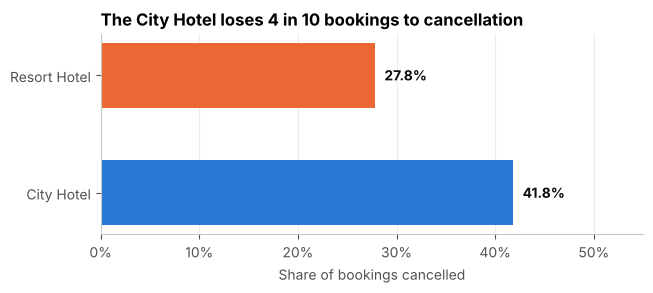

In [6]:
rates = df.groupby("hotel")["is_canceled"].mean()
fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(rates.index, rates.values, color=[HOTEL_COLORS[h] for h in rates.index], height=0.55)
for b, v in zip(bars, rates.values):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", color=INK, fontweight="bold")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 0.55); ax.grid(axis="y", visible=False)
ax.set_title("The City Hotel loses 4 in 10 bookings to cancellation")
ax.set_xlabel("Share of bookings cancelled")
save(fig, "01_cancel_rate_by_hotel"); plt.show()

## 4. What predicts a cancellation?

### 4.1 Lead time: the further ahead, the riskier

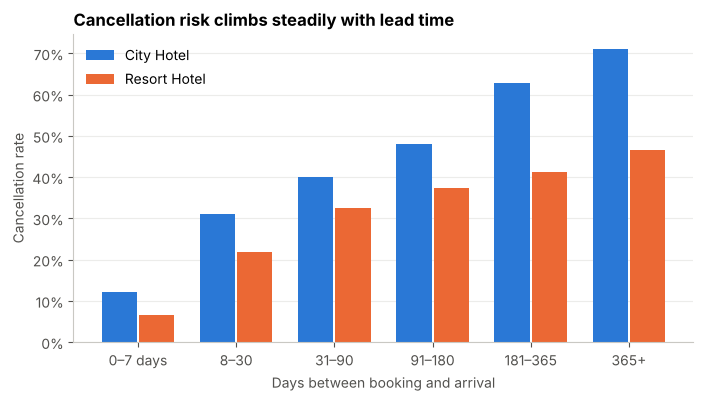

,bookings,cancel_rate
lead_bucket,,
0–7 days,19635,0.10
8–30,18945,0.28
31–90,29528,0.38
91–180,26420,0.45
181–365,21533,0.55
365+,3147,0.68


In [7]:
bins = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
labels = ["0–7 days", "8–30", "31–90", "91–180", "181–365", "365+"]
df["lead_bucket"] = pd.cut(df["lead_time"], bins=bins, labels=labels)
lead = df.groupby(["lead_bucket", "hotel"], observed=True)["is_canceled"].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(lead)); w = 0.38
for i, h in enumerate(lead.columns):
    ax.bar(x + (i - 0.5) * w, lead[h], width=w - 0.02, color=HOTEL_COLORS[h], label=h)
ax.set_xticks(x, lead.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Days between booking and arrival"); ax.set_ylabel("Cancellation rate")
ax.set_title("Cancellation risk climbs steadily with lead time")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
save(fig, "02_cancel_by_lead_time"); plt.show()

df.groupby("lead_bucket", observed=True)["is_canceled"].agg(bookings="size", cancel_rate="mean")

### 4.2 Deposit type: an unexpected result

In [8]:
df.groupby("deposit_type")["is_canceled"].agg(bookings="size", cancel_rate="mean")

,bookings,cancel_rate
deposit_type,,
No Deposit,104460,0.28
Non Refund,14586,0.99
Refundable,162,0.22


Non-refundable bookings cancel **99%** of the time, the opposite of what a deposit should do. Before drawing any conclusion, let's check *who* these bookings are:

In [9]:
nr = df[df["deposit_type"] == "Non Refund"]
other = df[df["deposit_type"] != "Non Refund"]
profile = pd.DataFrame({
    "Non Refund": [nr["country"].eq("PRT").mean(), nr["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(),
                   nr["lead_time"].median(), nr["total_of_special_requests"].mean(), nr["hotel"].eq("City Hotel").mean()],
    "All other bookings": [other["country"].eq("PRT").mean(), other["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(),
                           other["lead_time"].median(), other["total_of_special_requests"].mean(), other["hotel"].eq("City Hotel").mean()],
}, index=["Share from Portugal", "Share Groups / offline agents", "Median lead time (days)",
          "Avg special requests", "Share at City Hotel"])
profile

,Non Refund,All other bookings
Share from Portugal,0.97,0.33
Share Groups / offline agents,0.97,0.28
Median lead time (days),183.00,57.00
Avg special requests,0.00,0.65
Share at City Hotel,0.88,0.63


**Interpretation:** almost all "non-refundable" bookings are large, early, offline group/agency blocks from Portugal with zero special requests. This looks like **block allocations held by tour operators and released unused**, not individual guests losing a deposit. Two takeaways:
* The deposit is probably not being collected or enforced on these blocks. If so, it is a contract issue rather than a guest behaviour issue.
* It also explains why Portugal shows a high cancellation rate below: the country variable is mostly picking up these blocks.

### 4.3 Market segment, customer history and guest engagement

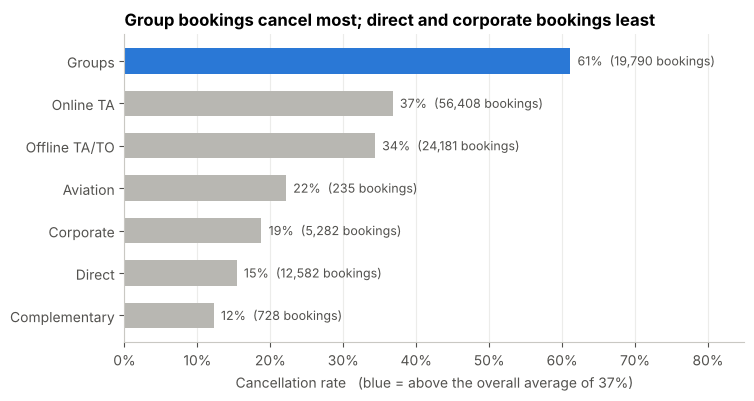

In [10]:
seg = (df[df["market_segment"] != "Undefined"]
       .groupby("market_segment")["is_canceled"].agg(bookings="size", cancel_rate="mean")
       .sort_values("cancel_rate"))
avg = df["is_canceled"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg.index, seg["cancel_rate"], color=[BLUE if r > avg else GREY for r in seg["cancel_rate"]], height=0.6)
for i, (r, n) in enumerate(zip(seg["cancel_rate"], seg["bookings"])):
    ax.text(r + 0.01, i, f"{r:.0%}  ({n:,} bookings)", va="center", color=MUTED, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, 0.85)
ax.grid(axis="y", visible=False)
ax.set_title("Group bookings cancel most; direct and corporate bookings least")
ax.set_xlabel(f"Cancellation rate   (blue = above the overall average of {avg:.0%})")
save(fig, "03_cancel_by_segment"); plt.show()

In [11]:
def rate_table(col, mapping=None):
    s = df[col] if mapping is None else df[col].map(mapping)
    return df.groupby(s)["is_canceled"].agg(bookings="size", cancel_rate="mean")

signals = pd.concat({
    "Previous cancellations": rate_table("previous_cancellations", lambda v: "Yes" if v > 0 else "No"),
    "Repeat guest": rate_table("is_repeated_guest", {0: "No", 1: "Yes"}),
    "Special requests": rate_table("total_of_special_requests", lambda v: "0" if v == 0 else "1+"),
    "Booking changed": rate_table("booking_changes", lambda v: "No" if v == 0 else "Yes"),
})
signals

bookings  cancel_rate
Previous cancellations No     112729         0.34
                       Yes      6479         0.92
Repeat guest           No     115454         0.38
                       Yes      3754         0.15
Special requests       0       70199         0.48
                       1+      49009         0.22
Booking changed        No     101232         0.41
                       Yes     17976         0.16

Bookings that were *changed* also cancel less (16% vs 41%), but changes happen after booking, so this is a sign of an engaged guest rather than something known up front.

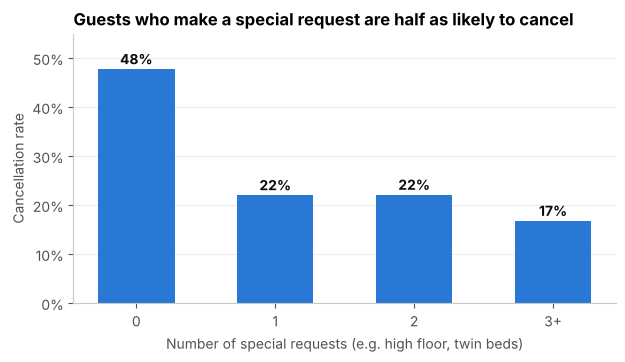

In [12]:
req = df.groupby(df["total_of_special_requests"].clip(upper=3))["is_canceled"].mean()
req.index = ["0", "1", "2", "3+"]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(req.index, req.values, color=BLUE, width=0.55)
for i, v in enumerate(req.values):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", color=INK, fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 0.55)
ax.set_xlabel("Number of special requests (e.g. high floor, twin beds)"); ax.set_ylabel("Cancellation rate")
ax.set_title("Guests who make a special request are half as likely to cancel")
ax.grid(axis="x", visible=False)
save(fig, "04_cancel_by_special_requests"); plt.show()

> **Note on car parking:** bookings that requested a parking space *never* cancelled (0%). Most likely the parking request is recorded at check-in, i.e. only for guests who actually arrived. It is a data-recording artefact, so it is **excluded** from the model in section 7 (it would leak the answer).

### 4.4 Country

In [13]:
top = df["country"].value_counts().head(10).index
ctry = (df[df["country"].isin(top)].groupby("country")["is_canceled"]
        .agg(bookings="size", cancel_rate="mean").sort_values("bookings", ascending=False))
ctry["cancel_rate_excl_non_refund"] = (df[df["country"].isin(top) & (df["deposit_type"] != "Non Refund")]
                                       .groupby("country")["is_canceled"].mean())
ctry

,bookings,cancel_rate,cancel_rate_excl_non_refund
country,,,
PRT,48482,0.57,0.39
GBR,12119,0.20,0.19
FRA,10401,0.19,0.19
ESP,8560,0.25,0.24
DEU,7285,0.17,0.17
ITA,3761,0.35,0.35
IRL,3374,0.25,0.25
BEL,2342,0.20,0.20
BRA,2222,0.37,0.37


Portugal's 57% cancellation rate falls to 39% once the non-refundable group blocks are removed. It is still the highest of the major markets, but the gap with other countries is much smaller than it first looks.

## 5. Seasonality and pricing

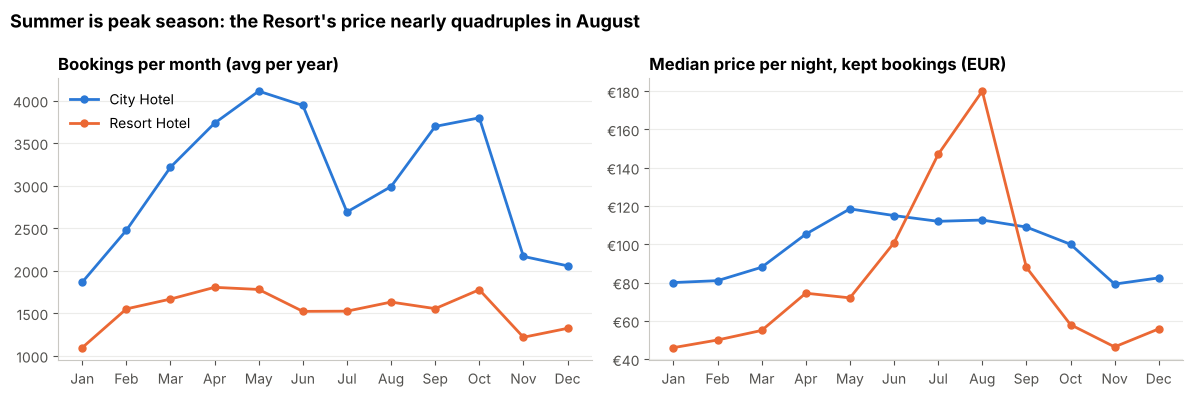

arrival_month,January,February,March,April,May,June,July,August,September,October,November,December
hotel,,,,,,,,,,,,
City Hotel,80.00,81.00,88.00,105.00,118.00,115.00,112.00,113.00,109.00,100.00,79.00,82.00
Resort Hotel,46.00,50.00,55.00,74.00,72.00,101.00,147.00,180.00,88.00,58.00,46.00,56.00


In [14]:
monthly = (df.groupby(["arrival_month", "hotel"], observed=True)
             .agg(bookings=("is_canceled", "size"), cancel_rate=("is_canceled", "mean"))
             .reset_index())
# average number of bookings per month (each month appears in 2 or 3 years of data)
years_per_month = df.groupby("arrival_month", observed=True)["arrival_date_year"].nunique()
monthly["bookings_per_year"] = monthly["bookings"] / monthly["arrival_month"].map(years_per_month).astype(float)

price = (df[(df["is_canceled"] == 0) & (df["nights"] > 0)]
         .groupby(["arrival_month", "hotel"], observed=True)["adr"].median().unstack())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for h, c in HOTEL_COLORS.items():
    m = monthly[monthly["hotel"] == h]
    axes[0].plot(m["arrival_month"].cat.codes, m["bookings_per_year"], color=c, lw=2, marker="o", ms=5, label=h)
    axes[1].plot(range(12), price[h].values, color=c, lw=2, marker="o", ms=5, label=h)
for ax in axes:
    ax.set_xticks(range(12), [m[:3] for m in month_order])
    ax.grid(axis="x", visible=False)
axes[0].set_title("Bookings per month (avg per year)")
axes[1].set_title("Median price per night, kept bookings (EUR)")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("€{x:,.0f}"))
axes[0].legend(frameon=False)
fig.suptitle("Summer is peak season: the Resort's price nearly quadruples in August", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "05_seasonality"); plt.show()

price.T.round(0)

## 6. Revenue at risk

Booking value = price per night (ADR) × number of nights. Summing it over cancelled bookings gives the room revenue that was booked and then lost (before any re-selling of the room).

In [15]:
rev = df.groupby("hotel").apply(lambda g: pd.Series({
    "booked_value": g["booking_value"].sum(),
    "cancelled_value": g.loc[g["is_canceled"] == 1, "booking_value"].sum(),
}), include_groups=False)
rev.loc["Total"] = rev.sum()
rev["share_lost"] = rev["cancelled_value"] / rev["booked_value"]
months_of_data = df["arrival_date"].dt.to_period("M").nunique()
rev["lost_per_year"] = rev["cancelled_value"] / months_of_data * 12

fmt = rev.copy()
for c in ["booked_value", "cancelled_value", "lost_per_year"]:
    fmt[c] = fmt[c].map("€{:,.0f}".format)
fmt["share_lost"] = fmt["share_lost"].map("{:.1%}".format)
print(f"Period covered: {months_of_data} months")
fmt

Period covered: 26 months


,booked_value,cancelled_value,share_lost,lost_per_year
hotel,,,,
City Hotel,"€25,265,002","€10,879,660",43.1%,"€5,021,381"
Resort Hotel,"€17,443,811","€5,842,177",33.5%,"€2,696,390"
Total,"€42,708,813","€16,721,837",39.2%,"€7,717,771"


In [16]:
seg_rev = (df[df["is_canceled"] == 1].groupby("market_segment")["booking_value"].sum()
           .sort_values(ascending=False))
seg_rev_share = (seg_rev / seg_rev.sum()).to_frame("share_of_lost_revenue")
seg_rev_share["lost_value_eur"] = seg_rev
seg_rev_share.head(5)

,share_of_lost_revenue,lost_value_eur
market_segment,,
Online TA,0.61,"10,227,646.11"
Groups,0.17,"2,800,543.98"
Offline TA/TO,0.15,"2,486,958.15"
Direct,0.06,"993,409.82"
Corporate,0.01,"196,383.07"


## 7. Can we flag risky bookings in advance?

A model is useful only if it uses information **available when the booking is made**. Excluded on purpose:
* `reservation_status`, `reservation_status_date`: they *are* the outcome (leakage)
* `required_car_parking_spaces`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`: recorded or updated after booking, so they would not be known at decision time

In [17]:
features_cat = ["hotel", "arrival_date_month", "meal", "market_segment", "distribution_channel",
                "deposit_type", "customer_type", "reserved_room_type", "country_grp"]
features_num = ["lead_time", "arrival_date_week_number", "stays_in_weekend_nights", "stays_in_week_nights",
                "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
                "previous_bookings_not_canceled", "adr", "total_of_special_requests", "has_agent", "has_company"]

top_countries = df["country"].value_counts().head(15).index
df["country_grp"] = np.where(df["country"].isin(top_countries), df["country"], "Other")

X = df[features_cat + features_num]
y = df["is_canceled"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)],
                        remainder="passthrough")
models = {
    "Logistic regression (baseline)": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42),
}
results, fitted = {}, {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)]).fit(X_train, y_train)
    results[name] = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    fitted[name] = pipe
pd.Series(results, name="ROC AUC (test set)").to_frame()

,ROC AUC (test set)
Logistic regression (baseline),0.87
Random forest,0.94


In [18]:
rf = fitted["Random forest"]
proba = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["Kept", "Cancelled"], digits=3))

# How useful is it operationally? Look at the 20% of bookings the model rates riskiest.
cut = np.quantile(proba, 0.80)
flag = proba >= cut
print(f"Top 20% riskiest bookings: {y_test[flag].mean():.0%} actually cancelled "
      f"(vs {y_test.mean():.0%} on average), capturing {y_test[flag].sum() / y_test.sum():.0%} of all cancellations.")

              precision    recall  f1-score   support

        Kept      0.858     0.934     0.895     18753
   Cancelled      0.869     0.738     0.798     11049

    accuracy                          0.862     29802
   macro avg      0.863     0.836     0.846     29802
weighted avg      0.862     0.862     0.859     29802

Top 20% riskiest bookings: 97% actually cancelled (vs 37% on average), capturing 53% of all cancellations.


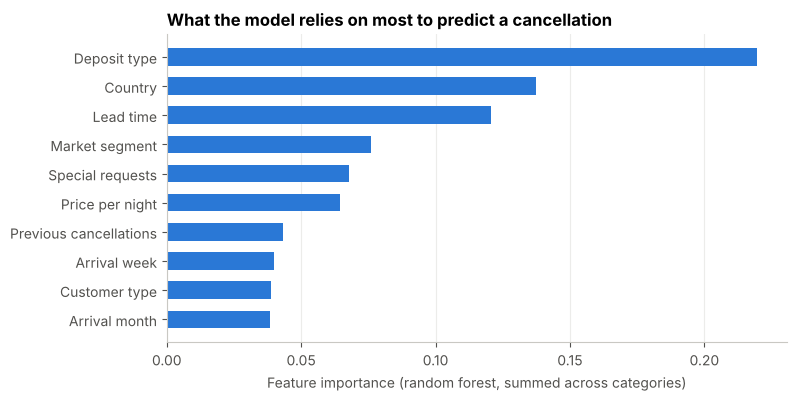

In [19]:
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)
# fold one-hot columns back into their original feature
imp.index = [n.split("__", 1)[1] for n in imp.index]
group = {c: next((f for f in features_cat if c.startswith(f + "_")), c) for c in imp.index}
imp = imp.groupby(group).sum().sort_values()

readable = {"lead_time": "Lead time", "deposit_type": "Deposit type", "adr": "Price per night",
            "country_grp": "Country", "arrival_date_week_number": "Arrival week",
            "total_of_special_requests": "Special requests", "market_segment": "Market segment",
            "stays_in_week_nights": "Weeknights", "previous_cancellations": "Previous cancellations",
            "customer_type": "Customer type", "stays_in_weekend_nights": "Weekend nights",
            "arrival_date_month": "Arrival month", "reserved_room_type": "Room type",
            "distribution_channel": "Distribution channel", "has_agent": "Booked via agent",
            "adults": "Adults", "meal": "Meal plan", "hotel": "Hotel"}
top_imp = imp.tail(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([readable.get(i, i) for i in top_imp.index], top_imp.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False)
ax.set_title("What the model relies on most to predict a cancellation")
ax.set_xlabel("Feature importance (random forest, summed across categories)")
save(fig, "06_feature_importance"); plt.show()

**Model takeaways**
* Using only information available at booking time, the random forest reaches a **ROC AUC of 0.94** on unseen bookings (logistic-regression baseline: 0.87).
* The top drivers match the exploratory analysis: lead time, deposit type, country, price and special requests.
* Ranking bookings by risk is the practical use: the riskiest 20% of bookings cancel **97%** of the time and contain over half of all cancellations. Many of them are the non-refundable group blocks from section 4.2, so in practice the model doubles as a detector for blocks likely to be released.

## 8. Conclusions and recommendations

**Key findings**
1. **37% of bookings are cancelled**: 42% at the City Hotel, 28% at the Resort.
2. **Lead time is one of the clearest signals:** bookings made a week ahead cancel under 10% of the time; bookings made 6+ months ahead cancel more than half the time.
3. **"Non-refundable" bookings cancel 99% of the time.** They are mostly offline group/tour-operator blocks from Portugal, which points to block allocations being released without the deposit being enforced.
4. **Engagement predicts commitment:** guests with a special request cancel 22% vs 48% without; repeat guests 15%; direct and corporate bookers 15–19%. Guests with a prior cancellation cancel 92% of the time.
5. **€16.7M of booked room revenue was cancelled over 26 months (~39% of booked value, ~€7.7M per year).** Online travel agencies account for 61% of that lost value, groups and offline agents for another 32%.
6. A model using only booking-time information **predicts cancellations with ROC AUC 0.94**; its top-20% risk group cancels 97% of the time.

**Recommendations**
| # | Recommendation | Based on |
|---|---|---|
| 1 | **Review tour-operator / group block contracts**: add release deadlines (e.g. 30 days before arrival) and enforce the deposit on unreleased rooms. | Finding 3 |
| 2 | **Tier the cancellation policy by lead time**: free cancellation for short-lead bookings, a small deposit or partial refund window for bookings 90+ days out. | Finding 2 |
| 3 | **Send a reconfirmation message 2–4 weeks before arrival** to the bookings the model flags as high-risk, and release the room early if there is no reply. | Findings 2, 6 |
| 4 | **Use risk-based overbooking at the City Hotel**, sized by the predicted number of cancellations per night rather than a flat percentage. | Findings 1, 6 |
| 5 | **Encourage engagement after booking**: ask about preferences (bed type, arrival time) in the confirmation email. Guests who make a request are half as likely to cancel. | Finding 4 |
| 6 | **Grow direct and repeat business**: a loyalty discount for direct rebooking shifts mix toward the lowest-cancellation segments and avoids OTA commissions. | Findings 4, 5 |

**Limitations**
* Data covers two hotels in one country, 2015–2017; patterns may differ elsewhere or post-COVID.
* Revenue lost is an upper bound: some cancelled rooms may have been re-sold, which the data does not show.
* Correlation is not causation: e.g. special requests may signal commitment rather than cause it. An A/B test of the "ask for preferences" email would confirm recommendation 5.
* No booking ID, so duplicated rows cannot be verified as separate bookings.